In [ ]:
import sys
from pathlib import Path
print(sys.executable)

# math imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

/Users/codingfox/Documents/heart_machine_learning/myenv/bin/python


In [ ]:
# load stuff and print
matches =  list(Path.cwd().rglob("processed_cleveland.csv"))

# print(matches)

heart_data = matches[0]
df = pd.read_csv(heart_data)
#print(df)

features = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak']
X = df[features]
y = df['num']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Logistic Regression

/Users/codingfox/Documents/heart_machine_learning/myenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/codingfox/Documents/heart_machine_learning/myenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/codingfox/Documents/heart_machine_learning/myenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, l

Accuracy: 0.5409836065573771
Precision: [0.61702128 0.66666667 0.         0.18181818 0.        ]
Recall: [1.         0.16666667 0.         0.28571429 0.        ]


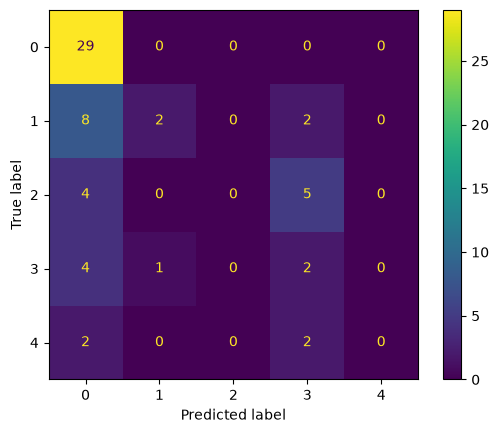

In [ ]:
model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(solver='liblinear', l1_ratio=1, C=0.1))
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average=None)
recall = recall_score(y_test, predictions, average=None)
print("Accuracy:" , accuracy)
print("Precision:", precision)
print("Recall:", recall)


# Create and Display Confusion Matrix
cm = confusion_matrix(y_test, predictions)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_display.plot()
plt.show()

Accuracy: 0.5081967213114754


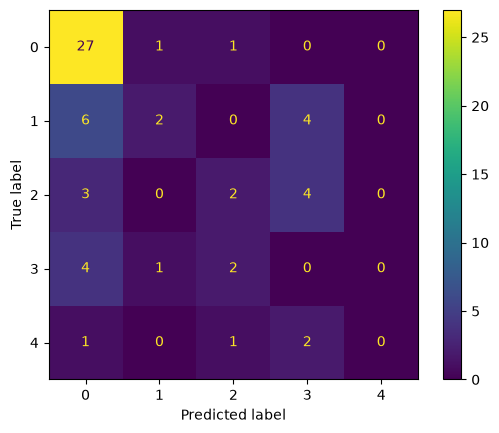

In [21]:
model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(solver='liblinear'))
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f'Accuracy: {accuracy}')

# Create and Display Confusion Matrix
cm = confusion_matrix(y_test, predictions)

cm_display = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_display.plot()
plt.show()

## Decision Tree

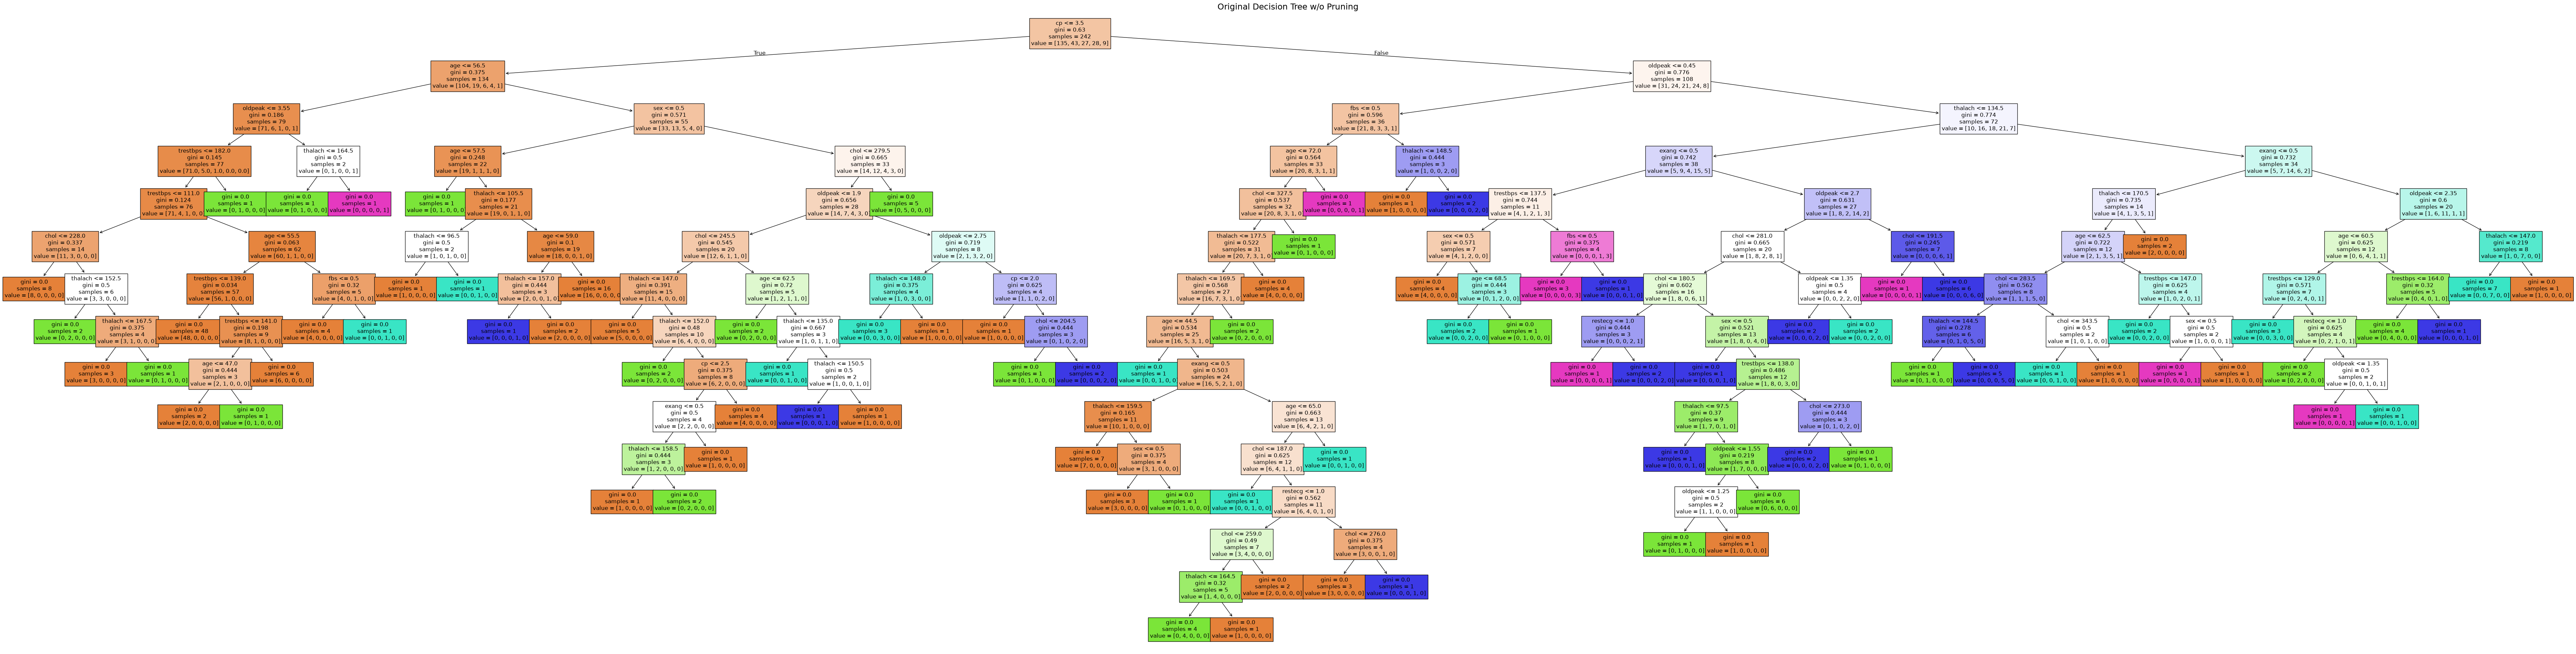

Accuracy w/o Pruning:  0.47540983606557374


In [19]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

plt.figure(figsize=(100,25))
tree.plot_tree(
    model, 
    feature_names=features,
    filled=True,
    fontsize=12
    )
plt.title("Original Decision Tree w/o Pruning", fontsize = 18)
plt.show()

original_accuracy = model.score(X_test, y_test)
print("Accuracy w/o Pruning: " , original_accuracy)

## Random Forest

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

